# 5.0 - Model: Logistic Regression (baseline variant)

**Training and evaluation of the Logistic Regression classifier on the baseline variant of the TF-IDF data.**

## Theoretical Foundation

Logistic Regression is a linear model that calculates a weighted sum of features `z = w * x + b` (token * learned weight + bias, which the model also learns), and then passes it through the sigmoid function `σ(z) = 1 / (1 + e^-z)` to obtain a probability between 0 and 1 (P >= 0.5 → positive | P < 0.5 → negative).

The model is trained by minimizing the cross-entropy (log-loss) between the predicted probabilities and the actual labels:

  - At the beginning, the model does not know the correct values of `w`; during training, it tries to find weights that produce the best possible predictions

  - For this, a loss function is used, i.e. log-loss / cross-entropy loss
  
    - If the actual class is positive and the model says P(positive) = 0.99 → excellent prediction → small loss
    - If the actual class is positive and the model says P(positive) = 0.01 → very incorrect prediction → large loss

Unlike Naive Bayes (which assumes feature independence and models the distribution of features by class), Logistic Regression directly learns the decision boundary - it does not need to model the entire joint distribution, only the combination of weights that best separates the classes.

## Why Regularization Is Particularly Important Here

Our vocabulary has `64.803` terms, while the training set has `39.665` reviews - therefore, there are more features than examples (the so-called `p > n` regime).

Ideally, the model should learn patterns that also appear in new reviews, but a highly flexible model could instead learn that a specific review contained specific words, and memorize exactly that.

In other words, without regularization, the model could almost trivially "memorize" the training set in such a large feature space (overfitting), without actually generalizing to new data.

Regularization essentially tells the model: "Don't just try to fit the training data as well as possible. You also pay a penalty if you use excessively large/complex coefficients."

Therefore, choosing the strength of regularization is fundamentally important here. We want neither:
  - too much regularization → the model becomes too simple
  - too little regularization → the model may overfit

## Processing Flow:

1. We load the previously prepared baseline TF-IDF data using the `load_variant()` function

2. We create a `LogisticRegression` classifier and define the `C` and `l1_ratio` hyperparameter values that `GridSearchCV` will examine

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - examines all combinations of hyperparameters from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the hyperparameter combination that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results

4. We analyze the terms with the largest positive and negative coefficients to determine which terms have the greatest influence on sentiment classification


In [1]:
import sys
sys.path.append("..")

import numpy as np
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.linear_model import LogisticRegression

## Loading the Data

We load the baseline variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("baseline")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 64803)
Test:  (9917, 64803)


## Model and Hyperparameters

Hyperparameters: `C` and `l1_ratio`

- `C` - inversely proportional to the strength of regularization (smaller `C` = stronger regularization, larger `C` = weaker regularization)

- `l1_ratio` - controls the balance between L2 and L1 regularization:
  - `l1_ratio=0.0` - pure L2 (Ridge) - evenly shrinks all coefficients toward zero, retains all features
  - `l1_ratio=1.0` - pure L1 (Lasso) - forces many coefficients exactly to zero, effectively performing automatic feature selection
  - Solver: we use `liblinear` - supports both L1 and L2 regularization, which we need to compare the two extreme variants.
  - Values between 0 and 1 ("true" elastic net) require `solver="saga"` - `liblinear` does not support them, so we test only the two extreme values

`max_iter`:
  - The maximum number of iterations the solver is allowed to perform while trying to find the optimal solution.
  - We increase it to 1000 (default is 100) to avoid convergence warnings in such a large feature space.


In [3]:
model = LogisticRegression(solver="liblinear", max_iter=1000, random_state=1)

param_grid = {
    "C": [0.01, 0.1, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0],
    "l1_ratio": [0.0, 1.0],
}

## Training and Evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `C` and `l1_ratio` values using 5-fold GridSearchCV on the training set, selects the combination with the best F1 score, then trains the best model on the entire training set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== logistic_regression (base) ==========
Best parameters: {'C': 6.0, 'l1_ratio': 0.0}
GridSearchCV time: 228.8s

Accuracy  : 0.9110
Precision : 0.9025
Recall    : 0.9222
F1        : 0.9123


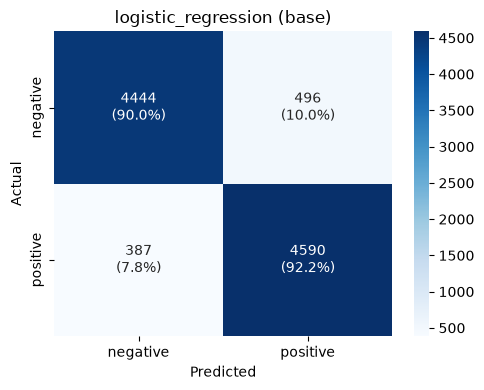


Saved:
  ..\models\logistic_regression_base.joblib
  ..\results\metrics\logistic_regression_base.json
  ..\results\figures\logistic_regression_base_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="logistic_regression",
    variant="base",
)

## Most Influential Terms (Coefficient Interpretation)**

Unlike Naive Bayes, the coefficients of Logistic Regression can be directly read as "how much the presence of this term pushes the prediction toward positive (positive coefficient) or negative (negative coefficient) sentiment".

This is a direct check of whether the process of preserving negations (`2_preprocessing.ipynb`) and bigrams (`3_vectorization.ipynb`) is actually being "used" by the model - we expect terms such as "not_good" - bigrams and negation words to be among the most influential for the negative class.

We load the saved model and vectorizer that we saved in the previous step and test them.

In [5]:
best_model = joblib.load("../models/logistic_regression_base.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_base.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = best_model.coef_[0]

top_positive_idx = np.argsort(coefficients)[-20:][::-1]
top_negative_idx = np.argsort(coefficients)[:20]

print("Top 20 terms most strongly associated with POSITIVE sentiment:")
for idx in top_positive_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

print("\nTop 20 terms most strongly associated with NEGATIVE sentiment:")
for idx in top_negative_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

n_zero_coefs = np.sum(coefficients == 0)
print(f"\nNumber of coefficients set exactly to 0: {n_zero_coefs} out of {len(coefficients)} ({n_zero_coefs / len(coefficients):.1%}) - relevant only if l1_ratio=1.0 (L1)")

Top 20 terms most strongly associated with POSITIVE sentiment:
  great                           +10.979
  excellent                       +10.967
  perfect                         +8.530
  amazing                         +7.989
  best                            +7.684
  wonderful                       +7.669
  hilarious                       +7.571
  loved                           +7.194
  today                           +7.115
  brilliant                       +7.017
  favorite                        +6.954
  fun                             +6.951
  superb                          +6.813
  must see                        +6.356
  enjoyed                         +6.329
  enjoyable                       +6.285
  one best                        +6.213
  well worth                      +5.946
  refreshing                      +5.936
  entertaining                    +5.888

Top 20 terms most strongly associated with NEGATIVE sentiment:
  worst                           -15.315
  awful  

## Conclusions

- Best `C`: 6.0, `l1_ratio`: 0.0

- Results:
  - Accuracy  : 0.9110
  - Precision : 0.9025
  - Recall    : 0.9222
  - F1        : 0.9123

- Most influential terms:
  -  largely match expectations (besides the expected words, negation unigrams and bigrams appear among the most influential)
  - For positive sentiment, terms such as: great, excellent, perfect, amazing and wonderful stand out especially
  - For positive sentiment, terms such as: worst, awful, bad, boring and waste stand out especially
- Statistical analysis from `3_vectorization.ipynb` (`min_df` experiment) where we showed that there are thousands of terms with moderate (not extreme) class deviation.
This aligns nicely with what we obtained here: terms with weak signals are better captured by L2, while L1 would partially discard them through aggressive deletion.